In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
from google.colab import files

uploaded = files.upload()

Saving Online_Retail_Excel_Cleaned.xlsx to Online_Retail_Excel_Cleaned.xlsx


In [19]:
df = pd.read_excel("Online_Retail_Excel_Cleaned.xlsx")

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalAmount,DataStatus
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,Keep
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,Keep
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,Keep
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,Keep
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,Keep


In [20]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (400916, 10)

Column Names:
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'CustomerID', 'Country', 'TotalAmount', 'DataStatus'],
      dtype='object')

Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
CustomerID     0
Country        0
TotalAmount    0
DataStatus     0
dtype: int64

Data Types:
Invoice                 int64
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
CustomerID              int64
Country                object
TotalAmount           float64
DataStatus             object
dtype: object


In [21]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2010-12-10 20:01:00


In [24]:
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'TotalAmount', 'DataStatus']


In [26]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'Invoice': 'nunique',
    'TotalAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346,165,11,372.86
12347,3,2,1323.32
12348,74,1,222.16
12349,43,3,2671.14
12351,11,1,300.93
12352,11,2,343.80
12353,44,1,317.76
12355,203,1,488.21
12356,16,3,3560.30


In [27]:
print("RFM Shape:", rfm.shape)

print("\nRFM Summary:")
print(rfm.describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

RFM Shape: (4312, 3)

RFM Summary:
           Recency    Frequency       Monetary
count  4312.000000  4312.000000    4312.000000
mean     91.171846     4.455705    2040.406712
std      96.860633     8.170213    8911.755977
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     307.187500
50%      53.000000     2.000000     701.615000
75%     136.000000     5.000000    1714.932500
max     374.000000   205.000000  349164.350000

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [28]:
rfm.to_excel("RFM_Analysis.xlsx")

print("RFM Analysis completed successfully!")

RFM Analysis completed successfully!


In [29]:
# Calculate RFM scores

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346,165,11,372.86,2,5,2
12347,3,2,1323.32,5,2,4
12348,74,1,222.16,2,1,1
12349,43,3,2671.14,3,3,5
12351,11,1,300.93,5,1,2
12352,11,2,343.80,5,2,2
12353,44,1,317.76,3,1,2
12355,203,1,488.21,1,1,2
12356,16,3,3560.30,4,3,5


In [30]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,165,11,372.86,2,5,2,252
12347,3,2,1323.32,5,2,4,524
12348,74,1,222.16,2,1,1,211
12349,43,3,2671.14,3,3,5,335
12351,11,1,300.93,5,1,2,512
12352,11,2,343.80,5,2,2,522
12353,44,1,317.76,3,1,2,312
12355,203,1,488.21,1,1,2,112
12356,16,3,3560.30,4,3,5,435


In [31]:
rfm['RFM_Total'] = (
    rfm['R_Score'].astype(int) +
    rfm['F_Score'].astype(int) +
    rfm['M_Score'].astype(int)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
CustomerID,,,,,,,,
12346,165,11,372.86,2,5,2,252,9
12347,3,2,1323.32,5,2,4,524,11
12348,74,1,222.16,2,1,1,211,4
12349,43,3,2671.14,3,3,5,335,11
12351,11,1,300.93,5,1,2,512,8


In [32]:
print(rfm[['R_Score', 'F_Score', 'M_Score', 'RFM_Total']].describe())

         RFM_Total
count  4312.000000
mean      9.000000
std       3.575283
min       3.000000
25%       6.000000
50%       9.000000
75%      12.000000
max      15.000000


In [33]:
def segment_customer(row):

    if row['R_Score'] >= 4 and row['F_Score'] >= 4 and row['M_Score'] >= 4:
        return 'Champions'

    elif row['R_Score'] >= 3 and row['F_Score'] >= 4:
        return 'Loyal Customers'

    elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
        return 'New Customers'

    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'

    elif row['R_Score'] <= 2 and row['F_Score'] <= 2:
        return 'Lost Customers'

    else:
        return 'Potential Loyalists'


rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment
CustomerID,,,,,,,,,
12346,165,11,372.86,2,5,2,252,9,At Risk
12347,3,2,1323.32,5,2,4,524,11,New Customers
12348,74,1,222.16,2,1,1,211,4,Lost Customers
12349,43,3,2671.14,3,3,5,335,11,Potential Loyalists
12351,11,1,300.93,5,1,2,512,8,New Customers
12352,11,2,343.80,5,2,2,522,9,New Customers
12353,44,1,317.76,3,1,2,312,6,Potential Loyalists
12355,203,1,488.21,1,1,2,112,4,Lost Customers
12356,16,3,3560.30,4,3,5,435,12,Potential Loyalists


In [34]:
segment_counts = rfm['Customer_Segment'].value_counts()

print(segment_counts)

Customer_Segment
Lost Customers         1025
Champions               911
Potential Loyalists     828
At Risk                 700
Loyal Customers         488
New Customers           360
Name: count, dtype: int64


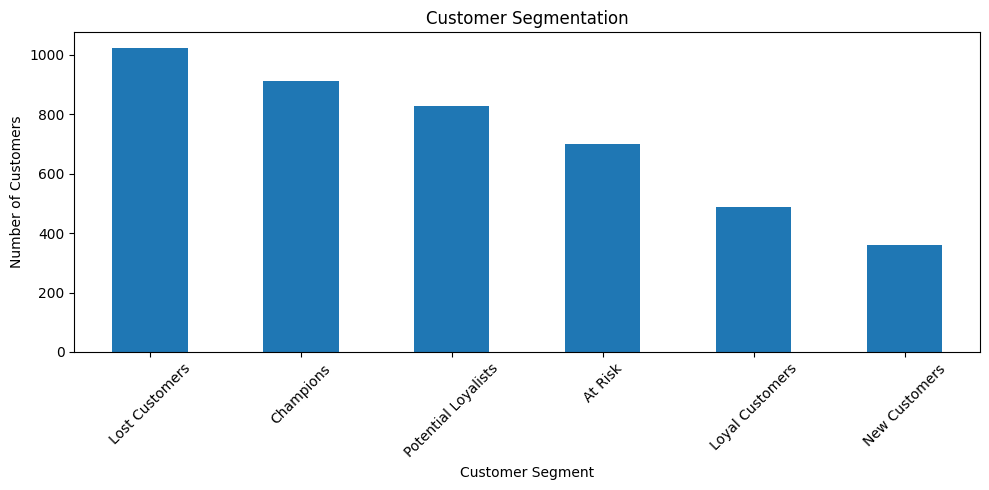

In [35]:
import matplotlib.pyplot as plt

segment_counts.plot(
    kind='bar',
    figsize=(10, 5),
    title='Customer Segmentation'
)

plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
segment_revenue = rfm.groupby('Customer_Segment')['Monetary'].sum()

print(segment_revenue.sort_values(ascending=False))

Customer_Segment
Champions              5647909.966
At Risk                1060864.341
Loyal Customers         890937.563
Potential Loyalists     607534.970
Lost Customers          414000.124
New Customers           176986.780
Name: Monetary, dtype: float64


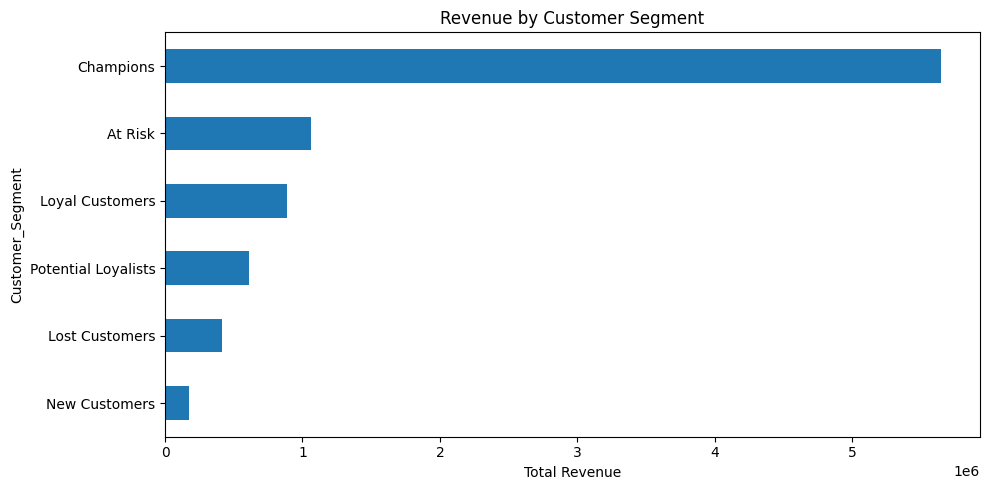

In [37]:
segment_revenue.sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    title='Revenue by Customer Segment'
)

plt.xlabel('Total Revenue')
plt.tight_layout()
plt.show()

In [38]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [39]:
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()

X.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,165,11,372.86
12347,3,2,1323.32
12348,74,1,222.16
12349,43,3,2671.14
12351,11,1,300.93


In [40]:
import numpy as np

X_log = np.log1p(X)

X_log.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,5.111988,2.484907,5.923881
12347,1.386294,1.098612,7.188654
12348,4.317488,0.693147,5.407889
12349,3.784190,1.386294,7.890635
12351,2.484907,0.693147,5.710195


In [41]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

In [42]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

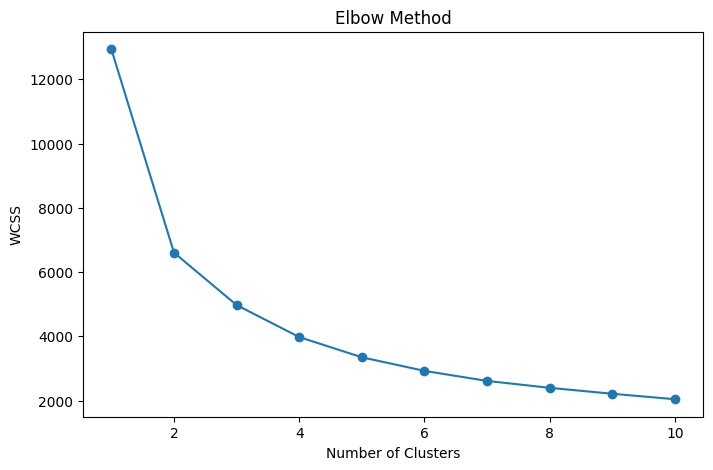

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.show()

In [44]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment,Cluster
CustomerID,,,,,,,,,,
12346,165,11,372.86,2,5,2,252,9,At Risk,3
12347,3,2,1323.32,5,2,4,524,11,New Customers,0
12348,74,1,222.16,2,1,1,211,4,Lost Customers,2
12349,43,3,2671.14,3,3,5,335,11,Potential Loyalists,3
12351,11,1,300.93,5,1,2,512,8,New Customers,0
12352,11,2,343.80,5,2,2,522,9,New Customers,0
12353,44,1,317.76,3,1,2,312,6,Potential Loyalists,0
12355,203,1,488.21,1,1,2,112,4,Lost Customers,2
12356,16,3,3560.30,4,3,5,435,12,Potential Loyalists,3


In [45]:
cluster_analysis = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Customer_Segment': 'count'
})

cluster_analysis.rename(
    columns={'Customer_Segment': 'Customer_Count'},
    inplace=True
)

print(cluster_analysis)

            Recency  Frequency     Monetary  Customer_Count
Cluster                                                    
0         23.947090   1.972487   532.078583             945
1         13.827763  13.556555  7381.581077             778
2        190.569666   1.298984   305.661388            1378
3         80.214699   4.138728  1759.990102            1211


In [46]:
final_df = rfm.reset_index()

final_df.to_excel(
    'Final_Customer_Segmentation.xlsx',
    index=False
)

print("Final dataset exported successfully!")

Final dataset exported successfully!


In [47]:
from google.colab import files

files.download('Final_Customer_Segmentation.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>